In [1]:
# Cell 1 - Settings: where everything lives
import os, shutil
from pathlib import Path

HDD      = Path("/media/hudaifa/Ventoy/datasets")
DACL_RAW = HDD / "dacl10k_raw"            # original dacl10k download (~5.2 GB)
MERGED   = HDD / "bridge_defects_yolo"    # final merged YOLO dataset (CODEBRIM + dacl10k)
CODEBRIM = Path.home() / "drone_ws/yolo/datasets/codebrim_yolo"
YOLO_DIR = Path.home() / "drone_ws/yolo"

CLASSES = ["crack", "spallation", "efflorescence", "exposed_bars", "corrosion_stain"]
MAX_SIDE = 640          # saved image size (long side) - we train at 640 anyway
SEED = 42

assert HDD.exists(), "Portable HDD not mounted - plug it in and run this cell again"
assert CODEBRIM.exists(), "CODEBRIM YOLO dataset not found"
DACL_RAW.mkdir(parents=True, exist_ok=True)

ram_gb = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
print(f"HDD free : {shutil.disk_usage(HDD).free / 2**30:.0f} GB")
print(f"PC RAM   : {ram_gb:.0f} GB")

HDD free : 919 GB
PC RAM   : 31 GB


In [2]:
# Cell 2 - Install the Hugging Face download tool (only needed once)
%pip install -q -U huggingface_hub
import huggingface_hub
print("huggingface_hub", huggingface_hub.__version__)

Note: you may need to restart the kernel to use updated packages.
huggingface_hub 2.2.0


In [2]:
# Cell 3 - Download dacl10k from Hugging Face to the HDD
os.environ["HF_HUB_CACHE"] = str(HDD / ".hf_cache")   # keep temp files on the HDD too
from huggingface_hub import snapshot_download

snapshot_download(repo_id="Voxel51/dacl10k", repo_type="dataset",
                  local_dir=DACL_RAW, max_workers=8)

n_jpg = sum(1 for _ in DACL_RAW.rglob("*.jpg"))
size_gb = sum(f.stat().st_size for f in DACL_RAW.rglob("*") if f.is_file()) / 2**30
print(f"Done: {n_jpg} images, {size_gb:.1f} GB in {DACL_RAW}")

/home/hudaifa/drone_ws/venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Fetching 8928 files: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 8928/8928 [55:11<00:00,  2.70it/s]


Done: 8923 images, 4.9 GB in /media/hudaifa/Ventoy/datasets/dacl10k_raw


In [3]:
# Cell 4 - Inspect the annotations: structure, splits, label names
import json
from collections import Counter

meta = json.loads((DACL_RAW / "samples.json").read_text())
samples = meta["samples"] if isinstance(meta, dict) else meta
print("top-level keys:", list(meta.keys()) if isinstance(meta, dict) else "list")
print("samples:", len(samples))

# one sample, long values shortened
first = samples[0]
print(json.dumps({k: (v if len(str(v)) < 250 else str(v)[:250] + " ...") for k, v in first.items()},
                 indent=1, default=str))

print("\nsplit tags:", Counter(t for s in samples for t in s.get("tags", [])))

label_fields = {k for s in samples[:200] for k, v in s.items() if isinstance(v, dict) and "_cls" in v}
print("label fields:", label_fields)
for f in sorted(label_fields):
    count = Counter()
    for s in samples:
        v = s.get(f) or {}
        for key in ("polylines", "detections"):
            for obj in v.get(key) or []:
                count[obj.get("label")] += 1
    print(f"\n{f}:")
    for name, n in count.most_common():
        print(f"   {name:25s} {n}")

top-level keys: ['samples']
samples: 8922
{
 "_id": {
  "$oid": "64ff63ea808d684d68ddf60d"
 },
 "filepath": "data/data_0/dacl10k_v2_train_1394.jpg",
 "tags": [
  "train"
 ],
 "metadata": {
  "_cls": "ImageMetadata",
  "size_bytes": 139035,
  "mime_type": "image/jpeg",
  "width": 1200,
  "height": 800,
  "num_channels": 3
 },
 "_media_type": "image",
 "_rand": 0.9999140295338379,
 "created_at": {
  "$date": "2023-09-11T19:00:37.665Z"
 },
 "created_date": {
  "$date": "2023-09-11T00:00:00Z"
 },
 "name": "dacl10k_v2_train_1394",
 "semseg_ground_truth_filled": "{'_cls': 'Polylines', 'polylines': [{'_id': {'$oid': '64ff63d5808d684d68dbf3c0'}, '_cls': 'Polyline', 'attributes': {}, 'tags': [], 'label': 'Hollowareas', 'points': [[[0.43583333333333335, 0.295], [0.4375, 0.295], [0.47333333333333333, 0.3075], [0.4 ...",
 "od_ground_truth": "{'_cls': 'Detections', 'detections': [{'_id': {'$oid': '64ff63d5808d684d68dbf3bf'}, '_cls': 'Detection', 'attributes': {}, 'tags': [], 'label': 'Hollowareas',

In [4]:
# Cell 5 - Classes, class mapping and the train/val/test plan
import random
from collections import Counter, defaultdict

# Model A: all 19 dacl10k labels (official dacl10k order)
DACL19 = ["Crack", "ACrack", "Wetspot", "Efflorescence", "Rust", "Rockpocket", "Hollowareas",
          "Cavity", "Spalling", "Graffiti", "Weathering", "Restformwork", "ExposedRebars",
          "Bearing", "EJoint", "Drainage", "PEquipment", "JTape", "WConccor"]

# Model B: our 5 defect classes (same order as CODEBRIM) and how dacl10k labels map onto them
CLASSES5 = ["crack", "spallation", "efflorescence", "exposed_bars", "corrosion_stain"]
TO5 = {"Crack": 0, "ACrack": 0, "Spalling": 1, "Efflorescence": 2, "ExposedRebars": 3, "Rust": 4}

# For the CODEBRIM outside test of model A: CODEBRIM class id -> dacl10k class id
CB_TO_19 = {0: DACL19.index("Crack"), 1: DACL19.index("Spalling"),
            2: DACL19.index("Efflorescence"), 3: DACL19.index("ExposedRebars"),
            4: DACL19.index("Rust")}

OUT19 = HDD / "dacl19_yolo"          # dataset for model A
OUT5 = HDD / "bridge5_yolo"          # dataset for model B (dacl10k + CODEBRIM)
OUT_CB19 = HDD / "codebrim_test19"   # CODEBRIM test photos with dacl10k class ids
BACKGROUND_FRACTION = 0.10           # defect-free photos, as a share of photos with labels

# 1. collect every labelled photo with its boxes (FiftyOne box = [x, y, w, h], 0..1)
records, no_labels, unknown = [], Counter(), Counter()
for s in samples:
    tag = (s.get("tags") or ["?"])[0]
    gt = s.get("od_ground_truth")
    if not gt:                               # no annotation at all (e.g. testdev)
        no_labels[tag] += 1
        continue
    boxes = []
    for d in gt.get("detections") or []:
        if d["label"] in DACL19:
            boxes.append((d["label"], *d["bounding_box"]))
        else:
            unknown[d["label"]] += 1
    records.append({"name": s["name"], "path": DACL_RAW / s["filepath"], "tag": tag,
                    "w": s["metadata"]["width"], "h": s["metadata"]["height"], "boxes": boxes})

by_tag = defaultdict(list)
for r in records:
    by_tag[r["tag"]].append(r)
print("labelled photos per split  :", {k: len(v) for k, v in by_tag.items()})
print("photos without labels      :", dict(no_labels))
if unknown:
    print("labels not in the 19 list  :", dict(unknown))

# 2. split plan
rng = random.Random(SEED)
if by_tag.get("testdev"):                     # labelled testdev -> use the official split
    plan = {"train": by_tag["train"], "val": by_tag["validation"], "test": by_tag["testdev"]}
    print("split: official train / validation / testdev")
else:                                        # official validation becomes our test set,
    tr = sorted(by_tag["train"], key=lambda r: r["name"])   # 10% of train becomes val
    rng.shuffle(tr)
    n_val = round(len(tr) * 0.10)
    plan = {"train": tr[n_val:], "val": tr[:n_val], "test": by_tag["validation"]}
    print("split: 90% of train -> train, 10% of train -> val, official validation -> test")


# 3. which photos go into which dataset (all photos with labels + max 10% without)
def pick(recs, has_obj):
    pos = [r for r in recs if has_obj(r)]
    neg = sorted((r for r in recs if not has_obj(r)), key=lambda r: r["name"])
    random.Random(SEED).shuffle(neg)
    return {r["name"] for r in pos + neg[:int(len(pos) * BACKGROUND_FRACTION)]}


def has19(r):
    return len(r["boxes"]) > 0


def has5(r):
    return any(b[0] in TO5 for b in r["boxes"])


use19 = {k: pick(v, has19) for k, v in plan.items()}
use5 = {k: pick(v, has5) for k, v in plan.items()}

# 4. summary
print(f"\n{'':16s}{'train':>8s}{'val':>8s}{'test':>8s}")
print(f"{'photos A (19)':16s}" + "".join(f"{len(use19[k]):8d}" for k in plan))
print(f"{'photos B (5)':16s}" + "".join(f"{len(use5[k]):8d}" for k in plan) + "   + CODEBRIM")
print("\nboxes per class (model A):")
for c in DACL19:
    n = [sum(b[0] == c for r in plan[k] if r["name"] in use19[k] for b in r["boxes"]) for k in plan]
    tag = f"  -> {CLASSES5[TO5[c]]}" if c in TO5 else ""
    print(f"   {c:15s}" + "".join(f"{x:8d}" for x in n) + tag)

labelled photos per split  : {'train': 6935, 'validation': 975}
photos without labels      : {'testdev': 1012}
split: 90% of train -> train, 10% of train -> val, official validation -> test

                   train     val    test
photos A (19)       6241     694     975
photos B (5)        5625     627     864   + CODEBRIM

boxes per class (model A):
   Crack              2830     324     472  -> crack
   ACrack              352      24      48  -> crack
   Wetspot            1299     144     218
   Efflorescence      3101     349     515  -> efflorescence
   Rust              11729    1108    1883  -> corrosion_stain
   Rockpocket          477      48      92
   Hollowareas        1237     126     194
   Cavity             7309     810    1152
   Spalling           7697     787    1400  -> spallation
   Graffiti           1712     168     320
   Weathering         3665     399     570
   Restformwork        769      82     171
   ExposedRebars      1603     150     247  -> exposed_b

In [5]:
# Cell 6 - Convert: shrink photos to 640 px and write YOLO labels for model A and model B
import cv2
from tqdm.auto import tqdm

MIN_BOX = 0.002          # ignore boxes thinner than 0.2% of the photo


def fresh(folder):
    if folder.exists():
        shutil.rmtree(folder)
    for split in ("train", "val", "test"):
        (folder / "images" / split).mkdir(parents=True)
        (folder / "labels" / split).mkdir(parents=True)


def read_small(path, w_meta, h_meta):
    """Read a photo (with EXIF rotation, like the annotators saw it), shrunk to ~MAX_SIDE."""
    reduce = max(w_meta, h_meta) / MAX_SIDE
    flag = (cv2.IMREAD_REDUCED_COLOR_8 if reduce >= 8 else cv2.IMREAD_REDUCED_COLOR_4
            if reduce >= 4 else cv2.IMREAD_REDUCED_COLOR_2 if reduce >= 2 else cv2.IMREAD_COLOR)
    img = cv2.imread(str(path), flag)
    if img is None:
        return None, "unreadable"
    h, w = img.shape[:2]
    status = "ok"
    if abs(w / h - w_meta / h_meta) > 0.02:
        status = "rotated (exif)" if abs(h / w - w_meta / h_meta) < 0.02 else "odd shape"
    s = MAX_SIDE / max(h, w)
    if s < 1:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    return img, status


def yolo_line(cid, x, y, bw, bh):
    x1, y1 = max(0.0, x), max(0.0, y)
    x2, y2 = min(1.0, x + bw), min(1.0, y + bh)
    if x2 - x1 < MIN_BOX or y2 - y1 < MIN_BOX:
        return None
    return f"{cid} {(x1 + x2) / 2:.6f} {(y1 + y2) / 2:.6f} {x2 - x1:.6f} {y2 - y1:.6f}"


for folder in (OUT19, OUT5, OUT_CB19):
    fresh(folder)

status_count, odd = Counter(), []
# --- dacl10k -> model A (19 classes) and model B (5 classes) ---
for split, recs in plan.items():
    todo = [r for r in recs if r["name"] in use19[split] or r["name"] in use5[split]]
    for r in tqdm(todo, desc=f"dacl10k {split}"):
        img, status = read_small(r["path"], r["w"], r["h"])
        status_count[status] += 1
        if img is None:
            continue
        if status != "ok":
            odd.append((split, r["name"], status))
        jpg = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 92])[1].tobytes()
        name = f"dacl_{r['name']}"
        if r["name"] in use19[split]:
            lines = [yolo_line(DACL19.index(b[0]), *b[1:]) for b in r["boxes"]]
            (OUT19 / "images" / split / f"{name}.jpg").write_bytes(jpg)
            (OUT19 / "labels" / split / f"{name}.txt").write_text("\n".join(l for l in lines if l))
        if r["name"] in use5[split]:
            lines = [yolo_line(TO5[b[0]], *b[1:]) for b in r["boxes"] if b[0] in TO5]
            (OUT5 / "images" / split / f"{name}.jpg").write_bytes(jpg)
            (OUT5 / "labels" / split / f"{name}.txt").write_text("\n".join(l for l in lines if l))

# --- CODEBRIM -> model B (same split as before) + test set with dacl10k ids for model A ---
for split in ("train", "val", "test"):
    files = sorted((CODEBRIM / "images" / split).glob("*.jpg"))
    for f in tqdm(files, desc=f"CODEBRIM {split}"):
        img = cv2.imread(str(f))
        h, w = img.shape[:2]
        s = MAX_SIDE / max(h, w)
        if s < 1:
            img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
        jpg = cv2.imencode(".jpg", img, [cv2.IMWRITE_JPEG_QUALITY, 92])[1].tobytes()
        label = (CODEBRIM / "labels" / split / f"{f.stem}.txt").read_text().strip()
        name = f"cb_{f.stem}"
        (OUT5 / "images" / split / f"{name}.jpg").write_bytes(jpg)
        (OUT5 / "labels" / split / f"{name}.txt").write_text(label)
        if split == "test":
            lines19 = [f"{CB_TO_19[int(l.split()[0])]} {l.split(' ', 1)[1]}"
                       for l in label.splitlines() if l.strip()]
            (OUT_CB19 / "images" / "test" / f"{name}.jpg").write_bytes(jpg)
            (OUT_CB19 / "labels" / "test" / f"{name}.txt").write_text("\n".join(lines19))

print("photo status:", dict(status_count))
if odd:
    print(f"{len(odd)} photos were rotated or odd-shaped - first few:", odd[:5])
for folder in (OUT19, OUT5, OUT_CB19):
    n = {s: len(list((folder / "images" / s).glob("*.jpg"))) for s in ("train", "val", "test")}
    gb = sum(f.stat().st_size for f in folder.rglob("*") if f.is_file()) / 2**30
    print(f"{folder.name:20s} {n}  {gb:.2f} GB")

CODEBRIM test: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 169/169 [00:00<00:00, 221.29it/s]


photo status: {'ok': 7900, 'rotated (exif)': 10}
10 photos were rotated or odd-shaped - first few: [('train', 'dacl10k_v2_train_3558', 'rotated (exif)'), ('train', 'dacl10k_v2_train_3596', 'rotated (exif)'), ('train', 'dacl10k_v2_train_3526', 'rotated (exif)'), ('train', 'dacl10k_v2_train_3544', 'rotated (exif)'), ('train', 'dacl10k_v2_train_3563', 'rotated (exif)')]
dacl19_yolo          {'train': 6241, 'val': 694, 'test': 975}  0.68 GB
bridge5_yolo         {'train': 6408, 'val': 793, 'test': 1033}  0.69 GB
codebrim_test19      {'train': 0, 'val': 0, 'test': 169}  0.01 GB


wrote /media/hudaifa/Ventoy/datasets/dacl19_yolo/data.yaml
wrote /media/hudaifa/Ventoy/datasets/bridge5_yolo/data.yaml
wrote /media/hudaifa/Ventoy/datasets/codebrim_test19/data.yaml


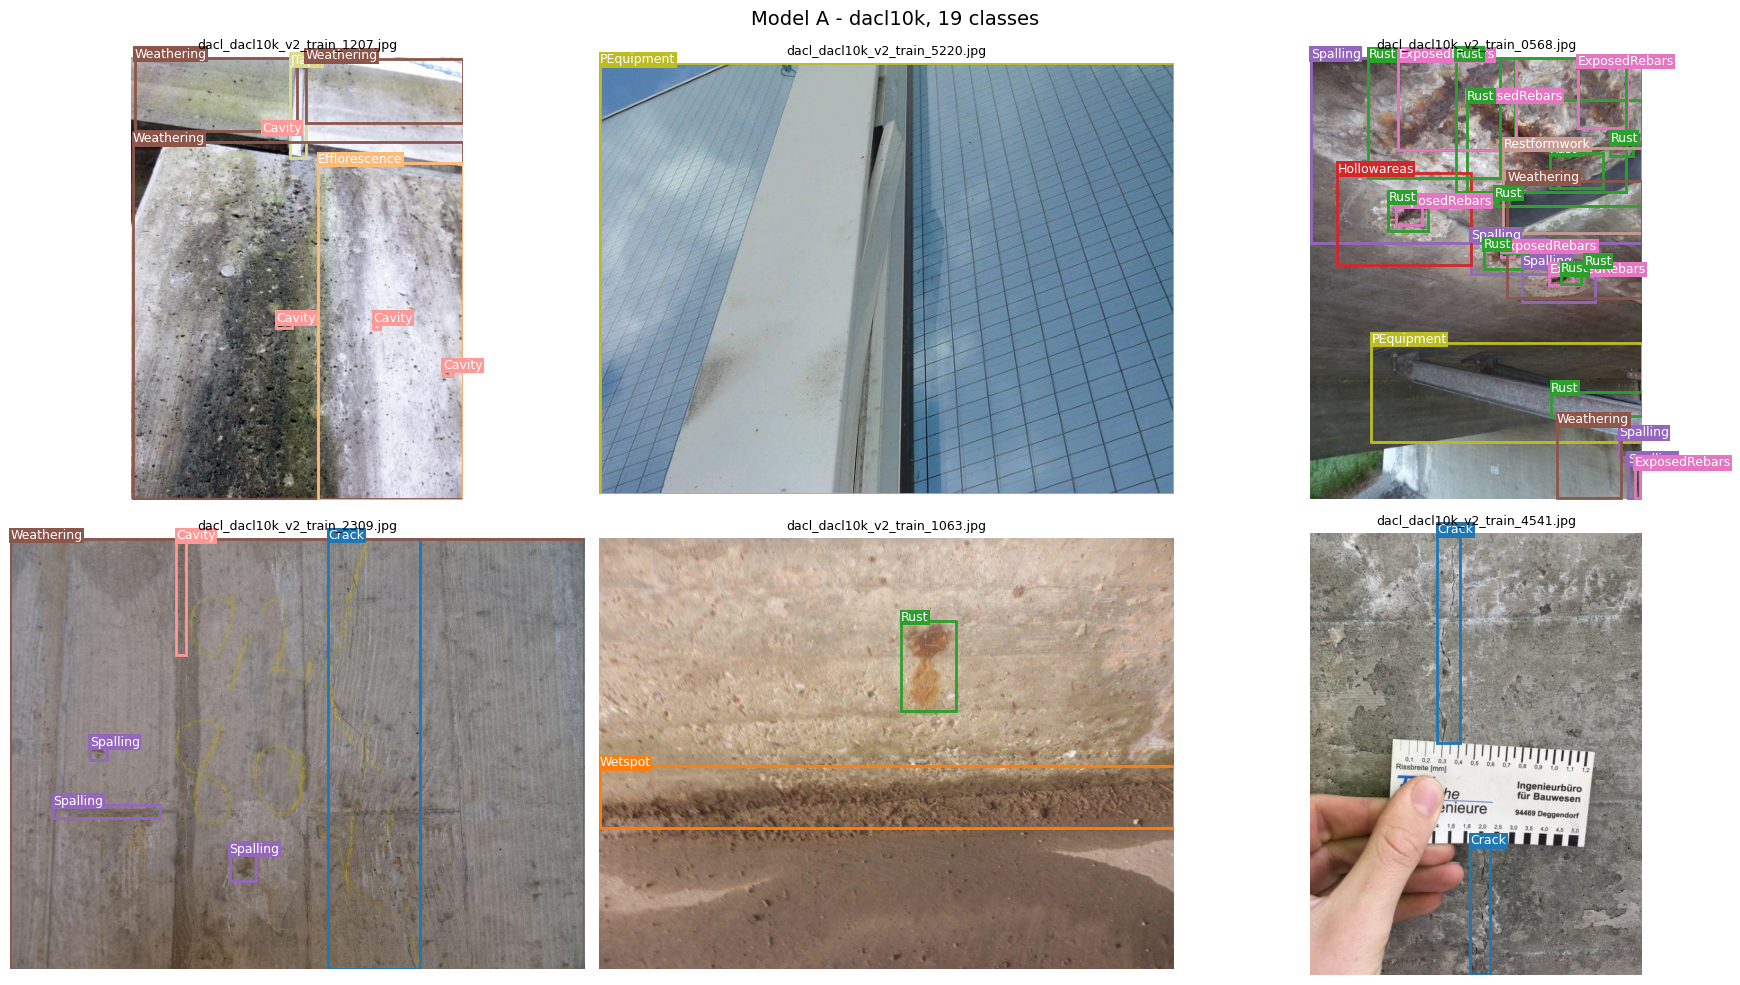

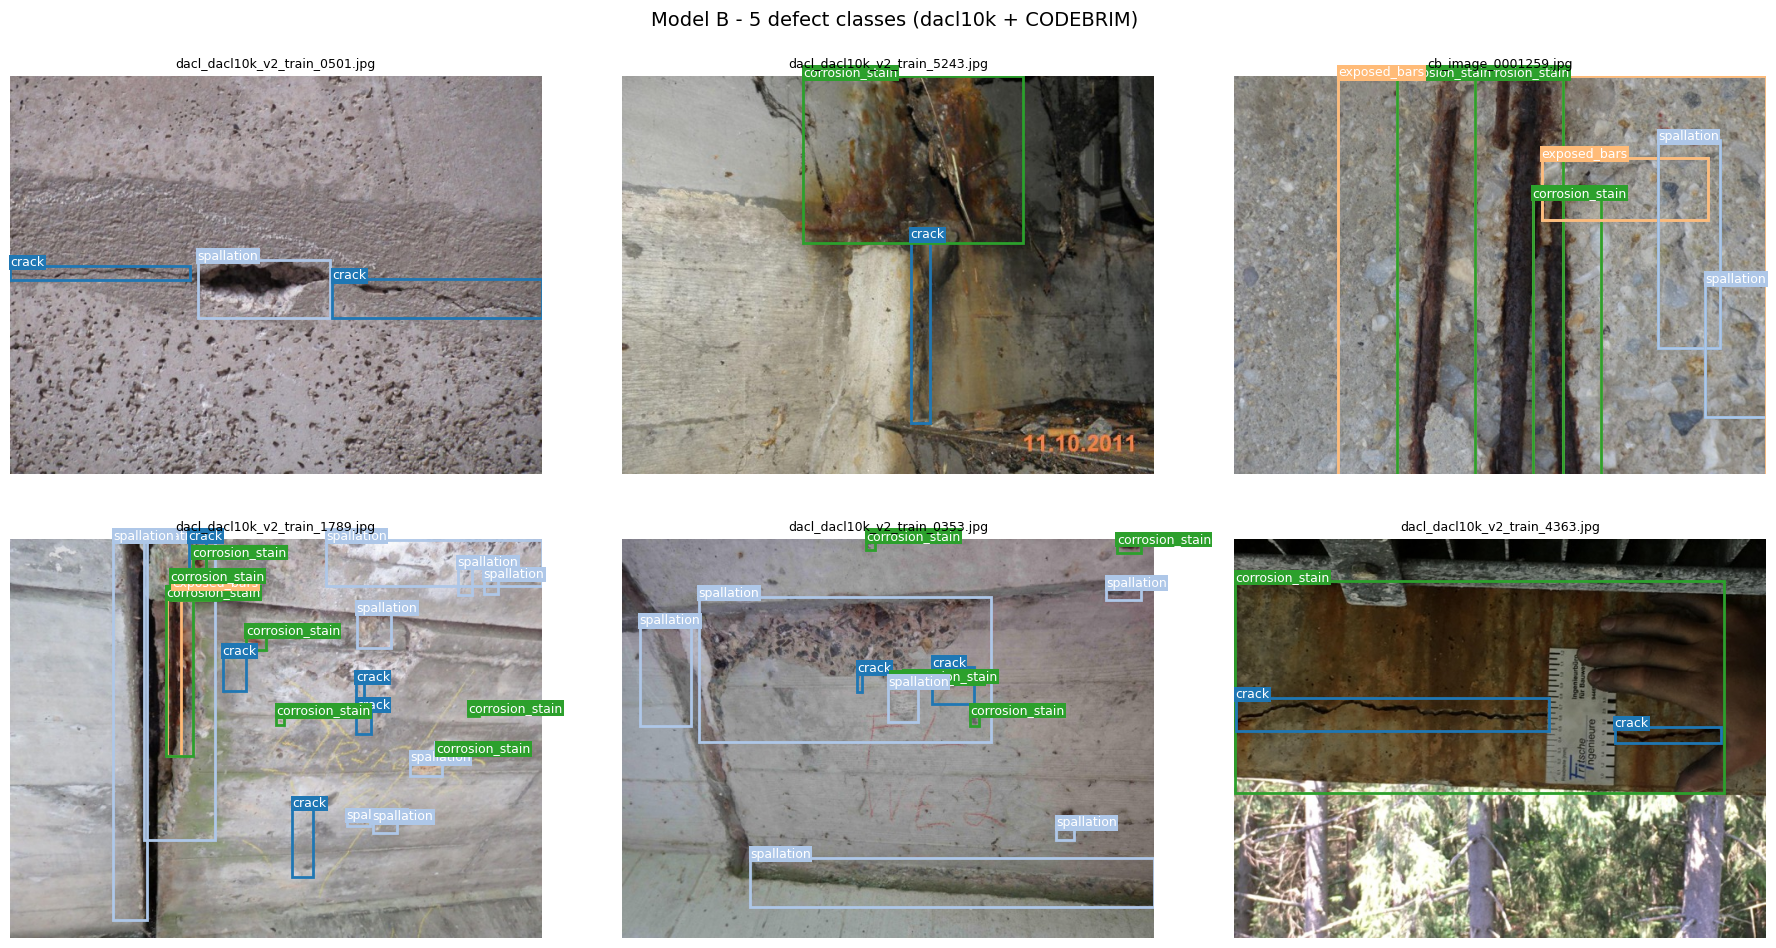

In [6]:
# Cell 7 - Write data.yaml files and show preview photos with their boxes
import matplotlib.pyplot as plt


def write_yaml(folder, names, train="images/train", val="images/val", test="images/test"):
    lines = [f"path: {folder}", f"train: {train}", f"val: {val}", f"test: {test}", "names:"]
    lines += [f"  {i}: {n}" for i, n in enumerate(names)]
    (folder / "data.yaml").write_text("\n".join(lines) + "\n")
    print("wrote", folder / "data.yaml")


write_yaml(OUT19, DACL19)
write_yaml(OUT5, CLASSES5)
write_yaml(OUT_CB19, DACL19, train="images/test", val="images/test")   # test-only set

COLORS = plt.cm.tab20.colors


def show_examples(folder, names, n=6, title=""):
    imgs = sorted((folder / "images" / "train").glob("*.jpg"))
    imgs = [p for p in imgs if (folder / "labels" / "train" / f"{p.stem}.txt").read_text().strip()]
    pick_ = random.Random(1).sample(imgs, min(n, len(imgs)))
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    for ax, p in zip(axes.flat, pick_):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        ax.imshow(img)
        for line in (folder / "labels" / "train" / f"{p.stem}.txt").read_text().splitlines():
            c, cx, cy, bw, bh = line.split()
            c, cx, cy, bw, bh = int(c), float(cx) * w, float(cy) * h, float(bw) * w, float(bh) * h
            ax.add_patch(plt.Rectangle((cx - bw / 2, cy - bh / 2), bw, bh, fill=False,
                                       lw=2, color=COLORS[c % 20]))
            ax.text(cx - bw / 2, cy - bh / 2, names[c], color="white", fontsize=9,
                    bbox=dict(facecolor=COLORS[c % 20], pad=1, lw=0))
        ax.set_title(p.name, fontsize=9)
        ax.axis("off")
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()


show_examples(OUT19, DACL19, title="Model A - dacl10k, 19 classes")
show_examples(OUT5, CLASSES5, title="Model B - 5 defect classes (dacl10k + CODEBRIM)")

In [7]:
# Cell 8 - Train model A: 19 classes, dacl10k only
from ultralytics import YOLO

model_a = YOLO(str(YOLO_DIR / "yolo11s.pt"))
model_a.train(data=str(OUT19 / "data.yaml"), imgsz=640, epochs=100, patience=30, batch=16,
              cache="ram", flipud=0.5, device=0, workers=8,
              project=str(YOLO_DIR / "runs"), name="dacl19_y11s", exist_ok=True)

Ultralytics 8.4.174 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060, 7796MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/media/hudaifa/Ventoy/datasets/dacl19_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/hudaifa/drone_ws/yolo/yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, n

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7aa8c2fcc3d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,

In [8]:
# Cell 9 - Train model B: 5 defect classes, dacl10k + CODEBRIM
import gc, torch
del model_a; gc.collect(); torch.cuda.empty_cache()      # free RAM/GPU from model A

model_b = YOLO(str(YOLO_DIR / "yolo11s.pt"))
model_b.train(data=str(OUT5 / "data.yaml"), imgsz=640, epochs=100, patience=30, batch=16,
              cache="ram", flipud=0.5, device=0, workers=8,
              project=str(YOLO_DIR / "runs"), name="bridge5_y11s", exist_ok=True)

Ultralytics 8.4.174 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060, 7796MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/media/hudaifa/Ventoy/datasets/bridge5_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/home/hudaifa/drone_ws/yolo/yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7aa926ef10f0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

ModuleNotFoundError: No module named 'pandas'

In [10]:
%pip install -q pandas


Note: you may need to restart the kernel to use updated packages.


In [11]:
# Cell 10 - Final test: every model on unseen test photos, one comparison table
import pandas as pd

MODEL_A = YOLO_DIR / "runs/dacl19_y11s/weights/best.pt"      # 19 classes
MODEL_B = YOLO_DIR / "runs/bridge5_y11s/weights/best.pt"     # 5 classes
MODEL_OLD = YOLO_DIR / "models/codebrim_y11s_640.pt"         # CODEBRIM-only model (0.412)
TEST_DIR = YOLO_DIR / "runs/final_test"

# test-set lists: dacl10k test photos only / CODEBRIM test photos only (for model B)
test_imgs = sorted((OUT5 / "images/test").glob("*.jpg"))
(OUT5 / "test_dacl.txt").write_text("\n".join(str(p) for p in test_imgs if p.name.startswith("dacl_")))
(OUT5 / "test_cb.txt").write_text("\n".join(str(p) for p in test_imgs if p.name.startswith("cb_")))
for part in ("dacl", "cb"):
    write_yaml(OUT5, CLASSES5, test=f"test_{part}.txt")
    (OUT5 / f"data_test_{part}.yaml").write_text((OUT5 / "data.yaml").read_text())
write_yaml(OUT5, CLASSES5)                     # restore the normal data.yaml

# where each of our 5 classes sits in each model
ID19 = {c: DACL19.index(n) for c, n in
        zip(CLASSES5, ["Crack", "Spalling", "Efflorescence", "ExposedRebars", "Rust"])}
ID5 = {c: i for i, c in enumerate(CLASSES5)}


def run(model_path, data_yaml, ids, label, test_set):
    m = YOLO(str(model_path)).val(data=str(data_yaml), split="test", imgsz=640, device=0,
                                  plots=False, verbose=False, project=str(TEST_DIR),
                                  name=label.replace(" ", "_"), exist_ok=True)
    ap = dict(zip(m.box.ap_class_index.tolist(), m.box.ap50.tolist()))
    row = {"model": label, "test photos": test_set}
    row.update({c: ap.get(ids[c], float("nan")) for c in CLASSES5})
    row["mean (5)"] = sum(row[c] for c in CLASSES5) / len(CLASSES5)
    return row, m


rows = []
r, m_a_full = run(MODEL_A, OUT19 / "data.yaml", ID19, "A: 19 classes", "dacl10k test")
rows.append(r)
rows.append(run(MODEL_B, OUT5 / "data_test_dacl.yaml", ID5, "B: 5 classes", "dacl10k test")[0])
rows.append(run(MODEL_A, OUT_CB19 / "data.yaml", ID19, "A: 19 classes", "CODEBRIM test")[0])
rows.append(run(MODEL_B, OUT5 / "data_test_cb.yaml", ID5, "B: 5 classes", "CODEBRIM test")[0])
rows.append(run(MODEL_OLD, CODEBRIM / "data.yaml", ID5, "old: CODEBRIM only", "CODEBRIM test")[0])

table = pd.DataFrame(rows).set_index(["model", "test photos"]).round(3)
print("mAP50 per class on unseen test photos (5 shared defect classes)\n")
print(table.to_string())
print(f"\nModel A, all 19 classes on dacl10k test: mAP50 = {m_a_full.box.map50:.3f}, "
      f"mAP50-95 = {m_a_full.box.map:.3f}")
table.to_csv(TEST_DIR / "comparison.csv")
print("saved:", TEST_DIR / "comparison.csv")

wrote /media/hudaifa/Ventoy/datasets/bridge5_yolo/data.yaml
wrote /media/hudaifa/Ventoy/datasets/bridge5_yolo/data.yaml
wrote /media/hudaifa/Ventoy/datasets/bridge5_yolo/data.yaml
Ultralytics 8.4.174 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060, 7796MiB)
YOLO11s summary (fused): 100 layers, 9,420,153 parameters, 0 gradients, 21.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6256.2±1793.4 MB/s, size: 73.6 KB)
val: Scanning /media/hudaifa/Ventoy/datasets/dacl19_yolo/labels/test... 975 images, 9 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 975/975 1.3Kit/s 0.8s0.1ss
val: /media/hudaifa/Ventoy/datasets/dacl19_yolo/images/test/dacl_dacl10k_v2_validation_0555.jpg: 1 duplicate labels removed
val: New cache created: /media/hudaifa/Ventoy/datasets/dacl19_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 61/61 10.9it/s 5.6s0.2s
                   all        975       8164      0.388  

In [12]:
# Cell 11 - Old CODEBRIM-only model on dacl10k test photos (completes the table)
rows.append(run(MODEL_OLD, OUT5 / "data_test_dacl.yaml", ID5, "old: CODEBRIM only", "dacl10k test")[0])
table = pd.DataFrame(rows).set_index(["model", "test photos"]).round(3)
print(table.to_string())
table.to_csv(TEST_DIR / "comparison.csv")


Ultralytics 8.4.174 🚀 Python-3.10.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 4060, 7796MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 6909.2±1292.6 MB/s, size: 80.1 KB)
val: Scanning /media/hudaifa/Ventoy/datasets/bridge5_yolo/labels/test... 864 images, 78 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 864/864 1.4Kit/s 0.6s0.0ss
val: /media/hudaifa/Ventoy/datasets/bridge5_yolo/images/test/dacl_dacl10k_v2_validation_0555.jpg: 1 duplicate labels removed
val: New cache created: /media/hudaifa/Ventoy/datasets/bridge5_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 54/54 11.2it/s 4.8s0.2s
                   all        864       4563      0.114     0.0885     0.0315     0.0116
Speed: 0.2ms preprocess, 4.1ms inference, 0.0ms loss, 0.3ms postprocess per image
                                  crack  spallation  effloresc

In [13]:
shutil.copy(YOLO_DIR / "runs/bridge5_y11s/weights/best.pt", YOLO_DIR / "models/bridge5_y11s.pt")
shutil.copy(YOLO_DIR / "runs/dacl19_y11s/weights/best.pt", YOLO_DIR / "models/dacl19_y11s.pt")
print(sorted(p.name for p in (YOLO_DIR / "models").glob("*.pt")))

['best.pt', 'bridge5_y11s.pt', 'codebrim_y11s_640.pt', 'dacl19_y11s.pt']
